# Mod_C
## Week 6

### Project: Cardiovascular Disease

This notebook continues the cardiovascular disease project developed in Module B.

Week 6 applies decision trees and random forests to the Statlog Heart Disease and Framingham Heart
Study datasets.

The analysis focuses on:

- Decision-tree structure and classification
- Entropy and information gain
- Decision-tree overfitting
- Maximum tree depth
- Minimum samples required for splitting and leaf nodes
- Random forests
- Bootstrap aggregation and feature randomization
- Random-forest hyperparameter tuning
- Feature importance

As in Weeks 4 and 5, the models address binary cardiovascular outcomes.

For Statlog, the goal is to predict whether heart disease is present using `target`.

For Framingham, the goal is to predict whether an individual develops coronary heart disease within
10 years using `TenYearCHD`.

Classification performance will be evaluated using accuracy, precision, recall, F1 score, and ROC AUC.

## Decision Trees

A decision tree classifies an observation by passing it through a sequence of decisions.

Each internal node asks a question about one predictor, such as whether age or blood pressure is above
or below a particular value.

Each answer sends the observation down a different branch of the tree.

Eventually, the observation reaches a leaf node. A leaf node makes the final prediction rather than
asking another question.

For classification, the leaf predicts a class such as heart disease present or absent.

Decision trees can model nonlinear relationships and interactions because different branches can apply
different rules to different portions of the data.

The quality of a potential split can be measured using entropy and information gain.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV,
    cross_validate
)

from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    OneHotEncoder
)

from sklearn.pipeline import Pipeline

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.ensemble import (
    RandomForestClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    make_scorer,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
from google.colab import files

uploaded = files.upload()

Saving preprocessed_framingham.csv to preprocessed_framingham.csv
Saving preprocessed_heart_disease.csv to preprocessed_heart_disease.csv


In [3]:
heart = pd.read_csv(
    "/content/preprocessed_heart_disease.csv"
)

framingham = pd.read_csv(
    "/content/preprocessed_framingham.csv"
)

print(
    "Heart Disease dataset shape:",
    heart.shape
)

print(
    "Framingham dataset shape:",
    framingham.shape
)

Heart Disease dataset shape: (270, 14)
Framingham dataset shape: (4238, 16)


## Outcome Distribution

The same binary cardiovascular outcomes used in Weeks 4 and 5 will be used for decision-tree and
random-forest classification.

Statlog is relatively balanced between its two classes.

Framingham contains substantially fewer positive TenYearCHD cases and is therefore an imbalanced
classification problem.

For this reason, accuracy will not be considered by itself. Recall, precision, F1 score, and ROC AUC
will also be examined.

In [5]:
print("Statlog target distribution:")
print(
    heart["target"].value_counts()
)

print("\nStatlog target percentages:")
print(
    heart["target"].value_counts(
        normalize=True
    ).round(3)
)

print("\nFramingham TenYearCHD distribution:")
print(
    framingham["TenYearCHD"].value_counts()
)

print("\nFramingham TenYearCHD percentages:")
print(
    framingham["TenYearCHD"].value_counts(
        normalize=True
    ).round(3)
)

Statlog target distribution:
target
0    150
1    120
Name: count, dtype: int64

Statlog target percentages:
target
0    0.556
1    0.444
Name: proportion, dtype: float64

Framingham TenYearCHD distribution:
TenYearCHD
0    3594
1     644
Name: count, dtype: int64

Framingham TenYearCHD percentages:
TenYearCHD
0    0.848
1    0.152
Name: proportion, dtype: float64


## Predictor Setup

The predictor structure from the previous classification analyses will be retained.

Continuous clinical measurements will remain numerical predictors.

Binary indicators will remain binary.

Statlog variables whose numerical values represent categories rather than continuous measurements will
be one-hot encoded. Education will similarly be treated as categorical in Framingham.

Unlike SVMs, decision trees and random forests do not require feature scaling because splits are based
on predictor thresholds rather than distances between observations.

In [6]:
# -----------------------------
# STATLOG
# -----------------------------

heart_numeric_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

heart_binary_features = [
    "sex",
    "fbs",
    "exang"
]

heart_categorical_features = [
    "cp",
    "restecg",
    "slope",
    "ca",
    "thal"
]

heart_features = (
    heart_numeric_features
    + heart_binary_features
    + heart_categorical_features
)


# -----------------------------
# FRAMINGHAM
# -----------------------------

framingham_numeric_features = [
    "age",
    "cigsPerDay",
    "totChol",
    "sysBP",
    "diaBP",
    "BMI",
    "heartRate",
    "glucose"
]

framingham_binary_features = [
    "male",
    "currentSmoker",
    "BPMeds",
    "prevalentStroke",
    "prevalentHyp",
    "diabetes"
]

framingham_categorical_features = [
    "education"
]

framingham_features = (
    framingham_numeric_features
    + framingham_binary_features
    + framingham_categorical_features
)

print(
    "Statlog predictors:",
    len(heart_features)
)

print(
    "Framingham predictors:",
    len(framingham_features)
)

Statlog predictors: 13
Framingham predictors: 15


## Train-Test Separation

The datasets will be separated into training and testing sets before model development.

A stratified split will maintain approximately the same positive and negative class proportions in both
sets.

The test sets will not be used to choose tree complexity, random-forest settings, or other
hyperparameters.

Entropy analysis, model-complexity experiments, and hyperparameter selection will use only the training
data. The held-out test data will be used afterward to evaluate the final prespecified models.

In [7]:
# -----------------------------
# STATLOG
# -----------------------------

heart_model_data = heart[
    heart_features + ["target"]
].dropna()

X_heart = heart_model_data[
    heart_features
]

y_heart = heart_model_data[
    "target"
]

X_heart_train, X_heart_test, y_heart_train, y_heart_test = train_test_split(
    X_heart,
    y_heart,
    test_size=0.20,
    random_state=42,
    stratify=y_heart
)


# -----------------------------
# FRAMINGHAM
# -----------------------------

framingham_model_data = framingham[
    framingham_features + ["TenYearCHD"]
].dropna()

X_framingham = framingham_model_data[
    framingham_features
]

y_framingham = framingham_model_data[
    "TenYearCHD"
]

X_framingham_train, X_framingham_test, y_framingham_train, y_framingham_test = train_test_split(
    X_framingham,
    y_framingham,
    test_size=0.20,
    random_state=42,
    stratify=y_framingham
)

print(
    "Statlog training size:",
    X_heart_train.shape
)

print(
    "Statlog testing size:",
    X_heart_test.shape
)

print(
    "Framingham training size:",
    X_framingham_train.shape
)

print(
    "Framingham testing size:",
    X_framingham_test.shape
)

Statlog training size: (216, 13)
Statlog testing size: (54, 13)
Framingham training size: (3390, 15)
Framingham testing size: (848, 15)


## Entropy and Information Gain

A decision tree must decide which feature and threshold should be used at each node.

Entropy measures how mixed the classes are within a node.

A pure node containing observations from only one class has low entropy.

A node containing a mixture of positive and negative observations has higher entropy.

Information gain measures how much entropy is reduced after a split.

A useful split creates child nodes that are more pure than the parent node. Therefore, decision trees
prefer splits that produce larger information gain.

The course notes define entropy using the natural logarithm. The calculation below follows that definition.

To demonstrate the concept using the cardiovascular datasets, a one-level decision tree will first identify
the preferred root split. The parent and child entropies will then be used to calculate information gain.

In [8]:
def create_tree_preprocessor(
    numeric_features,
    binary_features,
    categorical_features
):

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                "passthrough",
                numeric_features
            ),
            (
                "binary",
                "passthrough",
                binary_features
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ),
                categorical_features
            )
        ]
    )

    return preprocessor

In [9]:
def calculate_entropy(y):

    values, counts = np.unique(
        y,
        return_counts=True
    )

    probabilities = counts / counts.sum()

    entropy = -np.sum(
        probabilities
        * np.log(
            probabilities
        )
    )

    return entropy


def analyze_root_information_gain(
    X_train,
    y_train,
    numeric_features,
    binary_features,
    categorical_features,
    dataset_name
):

    preprocessor = create_tree_preprocessor(
        numeric_features,
        binary_features,
        categorical_features
    )

    X_transformed = preprocessor.fit_transform(
        X_train
    )

    feature_names = preprocessor.get_feature_names_out()

    stump = DecisionTreeClassifier(
        criterion="entropy",
        max_depth=1,
        random_state=42
    )

    stump.fit(
        X_transformed,
        y_train
    )

    root_feature_index = stump.tree_.feature[0]

    root_threshold = stump.tree_.threshold[0]

    root_feature = feature_names[
        root_feature_index
    ]

    feature_values = X_transformed[
        :,
        root_feature_index
    ]

    left_mask = (
        feature_values
        <= root_threshold
    )

    right_mask = (
        feature_values
        > root_threshold
    )

    y_array = np.asarray(
        y_train
    )

    y_left = y_array[
        left_mask
    ]

    y_right = y_array[
        right_mask
    ]

    parent_entropy = calculate_entropy(
        y_array
    )

    left_entropy = calculate_entropy(
        y_left
    )

    right_entropy = calculate_entropy(
        y_right
    )

    weighted_child_entropy = (
        len(y_left) / len(y_array)
    ) * left_entropy + (
        len(y_right) / len(y_array)
    ) * right_entropy

    information_gain = (
        parent_entropy
        - weighted_child_entropy
    )

    clean_feature_name = root_feature.split(
        "__",
        1
    )[-1]

    results = pd.DataFrame([{
        "Dataset": dataset_name,
        "Best Root Feature": clean_feature_name,
        "Threshold": root_threshold,
        "Parent Entropy": parent_entropy,
        "Left Entropy": left_entropy,
        "Right Entropy": right_entropy,
        "Information Gain": information_gain
    }]).round(4)

    display(
        results
    )

    return results

### Statlog Root Split

In [10]:
heart_information_gain = analyze_root_information_gain(
    X_heart_train,
    y_heart_train,
    heart_numeric_features,
    heart_binary_features,
    heart_categorical_features,
    "Statlog Heart Disease Dataset"
)

,Dataset,Best Root Feature,Threshold,Parent Entropy,Left Entropy,Right Entropy,Information Gain
0,Statlog Heart Disease Dataset,cp_3,0.5,0.687,0.5227,0.5841,0.137


#### Statlog Entropy and Information-Gain Interpretation

The first Statlog decision is based on `cp_3`, which represents whether the chest-pain category is 3.

The root split uses a threshold of 0.5, so the tree separates observations belonging to this category from
observations that do not.

The parent node has an entropy of 0.6870. After the split, the two child nodes have entropies of 0.5227
and 0.5841.

The resulting information gain is 0.1370.

This means that chest-pain category 3 provides useful information for separating the two heart-disease classes
at the beginning of the tree. The split reduces uncertainty compared with keeping all training observations in
one node.

### Framingham Root Split

In [11]:
framingham_information_gain = analyze_root_information_gain(
    X_framingham_train,
    y_framingham_train,
    framingham_numeric_features,
    framingham_binary_features,
    framingham_categorical_features,
    "Framingham Heart Study Dataset"
)

,Dataset,Best Root Feature,Threshold,Parent Entropy,Left Entropy,Right Entropy,Information Gain
0,Framingham Heart Study Dataset,age,48.5,0.426,0.2661,0.5338,0.023


#### Framingham Entropy and Information-Gain Interpretation

The preferred first split for Framingham is age at approximately 48.5 years.

The parent node has an entropy of 0.4260. After separating patients according to age, the younger branch has
an entropy of 0.2661 while the older branch has an entropy of 0.5338.

The resulting information gain is 0.0230.

The information gain is considerably smaller than the Statlog root split, indicating that no single first
decision separates Framingham CHD outcomes very strongly.

Age nevertheless provides the greatest entropy reduction available to the one-level tree and is therefore
selected as the first decision.

## Overfitting in Decision Trees

Decision trees can easily become too complex.

A very deep tree can continue creating increasingly specific rules until it nearly memorizes the training
data. This may produce excellent training performance but poor performance on new observations.

This is overfitting.

A tree that is too shallow can have the opposite problem. It may be too simple to capture meaningful
relationships. This is underfitting.

Several hyperparameters can control decision-tree complexity:

### Maximum Depth

`max_depth` limits the maximum number of levels in the tree.

A smaller depth creates a simpler model, while a very large depth allows increasingly specific rules.

### Minimum Samples Per Leaf

`min_samples_leaf` determines the minimum number of training observations that must remain in a leaf node.

Increasing this value prevents the tree from creating leaves that describe only a very small number of
observations.

### Minimum Samples Per Split

`min_samples_split` determines how many observations must exist in a node before the tree is allowed to
split that node again.

Increasing this value can prevent unnecessary splitting of small groups.

Cross-validation will be used to evaluate model complexity rather than selecting complexity based only on
training performance.

In [12]:
def get_tree_cv_metrics(
    pipeline,
    X_train,
    y_train
):

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scoring = {
        "accuracy": "accuracy",

        "precision": make_scorer(
            precision_score,
            zero_division=0
        ),

        "recall": make_scorer(
            recall_score,
            zero_division=0
        ),

        "f1": "f1",

        "roc_auc": "roc_auc"
    }

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    return scores

In [13]:
def analyze_tree_depth(
    X_train,
    y_train,
    numeric_features,
    binary_features,
    categorical_features,
    dataset_name
):

    depth_values = [
        2,
        3,
        5,
        8,
        None
    ]

    results = []

    for depth in depth_values:

        preprocessor = create_tree_preprocessor(
            numeric_features,
            binary_features,
            categorical_features
        )

        pipeline = Pipeline([
            (
                "preprocessing",
                preprocessor
            ),
            (
                "decision_tree",
                DecisionTreeClassifier(
                    criterion="entropy",
                    max_depth=depth,
                    class_weight="balanced",
                    random_state=42
                )
            )
        ])

        scores = get_tree_cv_metrics(
            pipeline,
            X_train,
            y_train
        )

        results.append({
            "Max Depth":
                "None" if depth is None else depth,

            "Mean Training F1":
                scores[
                    "train_f1"
                ].mean(),

            "Mean CV F1":
                scores[
                    "test_f1"
                ].mean(),

            "Mean CV Accuracy":
                scores[
                    "test_accuracy"
                ].mean(),

            "Mean CV ROC AUC":
                scores[
                    "test_roc_auc"
                ].mean()
        })

    results_df = pd.DataFrame(
        results
    ).round(3)

    print(
        dataset_name
    )

    display(
        results_df
    )

    return results_df

### Statlog Tree Depth

In [14]:
heart_depth_results = analyze_tree_depth(
    X_heart_train,
    y_heart_train,
    heart_numeric_features,
    heart_binary_features,
    heart_categorical_features,
    "Statlog Heart Disease Dataset"
)

Statlog Heart Disease Dataset


,Max Depth,Mean Training F1,Mean CV F1,Mean CV Accuracy,Mean CV ROC AUC
0,2,0.767,0.673,0.699,0.783
1,3,0.821,0.701,0.754,0.807
2,5,0.943,0.728,0.754,0.803
3,8,1.000,0.726,0.764,0.759
4,None,1.000,0.726,0.764,0.759


### Framingham Tree Depth

In [15]:
framingham_depth_results = analyze_tree_depth(
    X_framingham_train,
    y_framingham_train,
    framingham_numeric_features,
    framingham_binary_features,
    framingham_categorical_features,
    "Framingham Heart Study Dataset"
)

Framingham Heart Study Dataset


,Max Depth,Mean Training F1,Mean CV F1,Mean CV Accuracy,Mean CV ROC AUC
0,2,0.343,0.339,0.530,0.686
1,3,0.351,0.331,0.517,0.680
2,5,0.404,0.336,0.640,0.666
3,8,0.487,0.321,0.650,0.634
4,None,1.000,0.244,0.758,0.552


### Tree Depth and Overfitting

The following plots compare training F1 score with cross-validation F1 score at different tree depths.

A large gap between training and cross-validation performance can indicate overfitting.

In [16]:
def plot_tree_depth_results(
    results,
    dataset_name
):

    positions = np.arange(
        len(results)
    )

    labels = results[
        "Max Depth"
    ].astype(str)

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        positions,
        results["Mean Training F1"],
        marker="o",
        label="Training F1"
    )

    plt.plot(
        positions,
        results["Mean CV F1"],
        marker="o",
        label="5-Fold CV F1"
    )

    plt.xticks(
        positions,
        labels
    )

    plt.xlabel(
        "Maximum Tree Depth"
    )

    plt.ylabel(
        "F1 Score"
    )

    plt.title(
        f"{dataset_name}: Tree Depth and Overfitting"
    )

    plt.legend()

    plt.show()

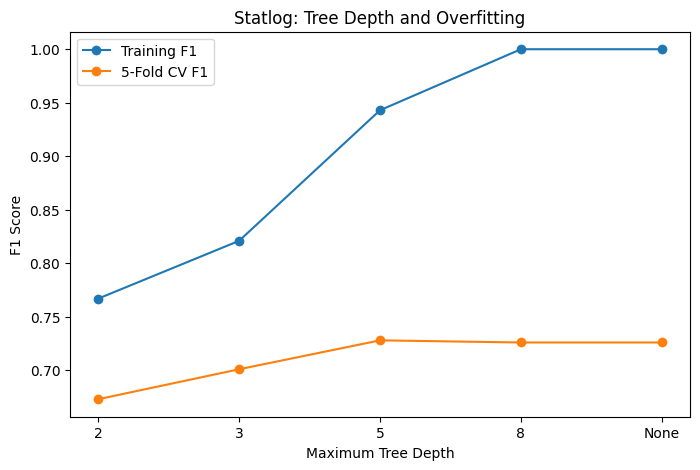

In [17]:
plot_tree_depth_results(
    heart_depth_results,
    "Statlog"
)

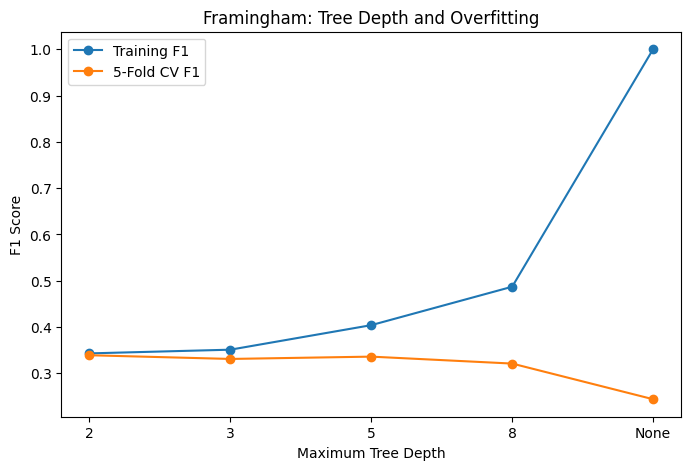

In [18]:
plot_tree_depth_results(
    framingham_depth_results,
    "Framingham"
)

### Tree-Depth Interpretation

The tree-depth experiments clearly demonstrate the risk of overfitting.

For Statlog, training F1 increased from 0.767 at depth 2 to 1.000 at depth 8 and with no depth limit.
However, cross-validation F1 did not continue improving. It reached approximately 0.728 at depth 5 and then
remained around 0.726 for the deepest trees.

This indicates that the very deep Statlog trees learned the training data perfectly without producing better
generalization.

The effect was even stronger for Framingham. The unrestricted tree achieved a training F1 of 1.000, but its
cross-validation F1 fell to only 0.244. In contrast, the shallow depth-2 tree achieved a much lower training
F1 of 0.343 but a substantially better cross-validation F1 of 0.339.

These results demonstrate why training performance alone should not determine tree complexity. Deep trees can
memorize increasingly specific patterns that do not generalize well to new observations.

## Random Forests

A random forest combines predictions from many decision trees rather than relying on one tree.

Individual decision trees can overfit because they may learn highly specific patterns from the training data.

Random forests reduce this problem by creating many different trees and combining their predictions.

Two important sources of randomness are used.

### Bootstrap Aggregation

Each tree is trained using a bootstrap sample of the training observations.

This means different trees see slightly different versions of the training data.

### Feature Randomization

At each potential split, a random subset of predictors is considered rather than allowing every tree to use
every feature at every decision.

This prevents the trees from all becoming nearly identical.

For classification, the predictions of the individual trees are combined to determine the forest's final
classification.

The result can generalize better than a single decision tree because errors from individual trees can be
reduced through aggregation.

## Random-Forest Feature Randomization

The effect of feature randomization will be examined using training-set cross-validation.

Two approaches will be compared:

- `max_features=None`: every transformed predictor can be considered at each split.
- `max_features="sqrt"`: only a random subset of approximately the square root of the available predictors
  can be considered at each split.

Both models will contain 300 trees and use bootstrap sampling.

The held-out test sets will not be used in this exploratory comparison.

In [19]:
def compare_rf_feature_randomization(
    X_train,
    y_train,
    numeric_features,
    binary_features,
    categorical_features,
    dataset_name
):

    settings = [
        (
            "All Features",
            None
        ),
        (
            "Random sqrt Subset",
            "sqrt"
        )
    ]

    results = []

    for setting_name, max_features_value in settings:

        preprocessor = create_tree_preprocessor(
            numeric_features,
            binary_features,
            categorical_features
        )

        pipeline = Pipeline([
            (
                "preprocessing",
                preprocessor
            ),
            (
                "random_forest",
                RandomForestClassifier(
                    n_estimators=300,
                    criterion="entropy",
                    max_features=max_features_value,
                    class_weight="balanced",
                    bootstrap=True,
                    random_state=42,
                    n_jobs=-1
                )
            )
        ])

        scores = get_tree_cv_metrics(
            pipeline,
            X_train,
            y_train
        )

        results.append({
            "Feature Strategy":
                setting_name,

            "Mean Training F1":
                scores[
                    "train_f1"
                ].mean(),

            "Mean CV F1":
                scores[
                    "test_f1"
                ].mean(),

            "Mean CV Accuracy":
                scores[
                    "test_accuracy"
                ].mean(),

            "Mean CV ROC AUC":
                scores[
                    "test_roc_auc"
                ].mean()
        })

    results_df = pd.DataFrame(
        results
    ).round(3)

    print(
        dataset_name
    )

    display(
        results_df
    )

    return results_df

### Statlog Random-Forest Feature Randomization

In [20]:
heart_rf_randomization_results = compare_rf_feature_randomization(
    X_heart_train,
    y_heart_train,
    heart_numeric_features,
    heart_binary_features,
    heart_categorical_features,
    "Statlog Heart Disease Dataset"
)

Statlog Heart Disease Dataset


,Feature Strategy,Mean Training F1,Mean CV F1,Mean CV Accuracy,Mean CV ROC AUC
0,All Features,1.0,0.792,0.819,0.884
1,Random sqrt Subset,1.0,0.789,0.819,0.897


#### Statlog Feature-Randomization Interpretation

For Statlog, allowing every feature to be considered at each split produced a cross-validation F1 score of
0.792, while using a random square-root subset produced a very similar F1 score of 0.789.

However, ROC AUC increased from 0.884 to 0.897 when feature randomization was used.

Both approaches achieved perfect training F1, showing that feature randomization by itself did not eliminate
the ability of the forest to fit the training data very closely.

The results suggest that feature randomization did not materially improve Statlog F1 in this initial experiment,
although it modestly improved the model's ability to rank positive and negative cases.

### Framingham Random-Forest Feature Randomization

In [21]:
framingham_rf_randomization_results = compare_rf_feature_randomization(
    X_framingham_train,
    y_framingham_train,
    framingham_numeric_features,
    framingham_binary_features,
    framingham_categorical_features,
    "Framingham Heart Study Dataset"
)

Framingham Heart Study Dataset


,Feature Strategy,Mean Training F1,Mean CV F1,Mean CV Accuracy,Mean CV ROC AUC
0,All Features,1.0,0.127,0.85,0.688
1,Random sqrt Subset,1.0,0.096,0.85,0.701


#### Framingham Feature-Randomization Interpretation

For Framingham, using all features at every split produced a cross-validation F1 score of 0.127, compared with
0.096 when a random square-root subset was used.

However, feature randomization increased ROC AUC from 0.688 to 0.701.

As with Statlog, both forests achieved a training F1 of 1.000. This shows that feature randomization alone does
not guarantee that overfitting disappears.

Instead, random forests reduce the dependence on any single tree by creating diverse trees and aggregating their
predictions. Additional complexity controls such as maximum depth and minimum leaf size can still be useful.

## Decision-Tree Hyperparameter Tuning

A decision tree that is allowed to grow without restrictions can overfit the training data.

Stratified 5-fold cross-validation will therefore be used to select:

- Maximum tree depth
- Minimum samples required to split a node
- Minimum samples required in each leaf
- Whether balanced class weighting should be used

F1 score will be used as the primary selection metric because the Framingham positive class is relatively
uncommon.

The held-out test set will not be used during hyperparameter selection.

In [47]:
def tune_decision_tree(
    X_train,
    y_train,
    numeric_features,
    binary_features,
    categorical_features,
    dataset_name
):

    preprocessor = create_tree_preprocessor(
        numeric_features,
        binary_features,
        categorical_features
    )

    pipeline = Pipeline([
        (
            "preprocessing",
            preprocessor
        ),
        (
            "decision_tree",
            DecisionTreeClassifier(
                criterion="entropy",
                random_state=42
            )
        )
    ])

    parameter_grid = {
        "decision_tree__max_depth": [
            2,
            3,
            5,
            8,
            None
        ],

        "decision_tree__min_samples_split": [
            2,
            10,
            20
        ],

        "decision_tree__min_samples_leaf": [
            1,
            5,
            10
        ],

        "decision_tree__class_weight": [
            None,
            "balanced"
        ]
    }

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    search = GridSearchCV(
        pipeline,
        param_grid=parameter_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1
    )

    search.fit(
        X_train,
        y_train
    )

    print(
        dataset_name
    )

    print(
        "Best parameters:"
    )

    print(
        search.best_params_
    )

    print(
        "Best CV F1:",
        round(
            search.best_score_,
            3
        )
    )

    return search

### Tuned Statlog Decision Tree

In [49]:
heart_tuned_tree = tune_decision_tree(
    X_heart_train,
    y_heart_train,
    heart_numeric_features,
    heart_binary_features,
    heart_categorical_features,
    "Statlog Heart Disease Dataset"
)

Statlog Heart Disease Dataset
Best parameters:
{'decision_tree__class_weight': None, 'decision_tree__max_depth': 3, 'decision_tree__min_samples_leaf': 10, 'decision_tree__min_samples_split': 2}
Best CV F1: 0.75


#### Tuned Statlog Decision-Tree Interpretation

Cross-validation selected a Statlog decision tree with:

- Maximum depth = 3
- Minimum samples per leaf = 10
- Minimum samples per split = 2
- Ordinary class weighting

The selected model achieved a cross-validation F1 score of 0.750.

The relatively shallow maximum depth and minimum leaf size of 10 restrict the tree from creating highly
specific branches containing only a few observations.

This is consistent with the earlier depth experiment, which showed that unrestricted trees could fit the
training data perfectly without improving cross-validation performance.

### Tuned Framingham Decision Tree

In [50]:
framingham_tuned_tree = tune_decision_tree(
    X_framingham_train,
    y_framingham_train,
    framingham_numeric_features,
    framingham_binary_features,
    framingham_categorical_features,
    "Framingham Heart Study Dataset"
)

Framingham Heart Study Dataset
Best parameters:
{'decision_tree__class_weight': 'balanced', 'decision_tree__max_depth': 2, 'decision_tree__min_samples_leaf': 1, 'decision_tree__min_samples_split': 2}
Best CV F1: 0.339


#### Tuned Framingham Decision-Tree Interpretation

Cross-validation selected a Framingham decision tree with:

- Maximum depth = 2
- Minimum samples per leaf = 1
- Minimum samples per split = 2
- Balanced class weighting

The selected model achieved a cross-validation F1 score of 0.339.

The maximum depth of only 2 is consistent with the earlier overfitting analysis. Deeper Framingham trees
increased training performance substantially while cross-validation performance declined.

Balanced class weighting was also selected because positive TenYearCHD cases are much less common than
negative cases. This gives the minority positive class greater influence during tree construction.

## Random-Forest Hyperparameter Tuning

Random forests also contain hyperparameters that control model complexity and diversity.

The following settings will be explored:

- `n_estimators`: number of trees in the forest
- `max_depth`: maximum depth of each tree
- `min_samples_split`: minimum observations required before a node can split
- `min_samples_leaf`: minimum observations required in a leaf
- `max_features`: number of predictors that may be considered at each split
- `class_weight`: whether the minority and majority classes receive equal or balanced importance

RandomizedSearchCV will be used rather than testing every possible combination. This reduces computation
while still examining a range of reasonable random-forest configurations.

Selection will use stratified 5-fold cross-validation and F1 score on the training data only.

In [25]:
def tune_random_forest(
    X_train,
    y_train,
    numeric_features,
    binary_features,
    categorical_features,
    dataset_name
):

    preprocessor = create_tree_preprocessor(
        numeric_features,
        binary_features,
        categorical_features
    )

    pipeline = Pipeline([
        (
            "preprocessing",
            preprocessor
        ),
        (
            "random_forest",
            RandomForestClassifier(
                criterion="entropy",
                bootstrap=True,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    parameter_distributions = {

        "random_forest__n_estimators": [
            200,
            400,
            600
        ],

        "random_forest__max_depth": [
            5,
            10,
            None
        ],

        "random_forest__min_samples_split": [
            2,
            10
        ],

        "random_forest__min_samples_leaf": [
            1,
            5,
            10
        ],

        "random_forest__max_features": [
            "sqrt",
            0.5
        ],

        "random_forest__class_weight": [
            None,
            "balanced"
        ]
    }

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    search = RandomizedSearchCV(
        pipeline,
        param_distributions=parameter_distributions,
        n_iter=12,
        scoring="f1",
        cv=cv,
        random_state=42,
        n_jobs=-1
    )

    search.fit(
        X_train,
        y_train
    )

    print(
        dataset_name
    )

    print(
        "Best parameters:"
    )

    print(
        search.best_params_
    )

    print(
        "Best CV F1:",
        round(
            search.best_score_,
            3
        )
    )

    return search

### Tuned Statlog Random Forest

In [26]:
heart_tuned_forest = tune_random_forest(
    X_heart_train,
    y_heart_train,
    heart_numeric_features,
    heart_binary_features,
    heart_categorical_features,
    "Statlog Heart Disease Dataset"
)

Statlog Heart Disease Dataset
Best parameters:
{'random_forest__n_estimators': 200, 'random_forest__min_samples_split': 10, 'random_forest__min_samples_leaf': 10, 'random_forest__max_features': 'sqrt', 'random_forest__max_depth': 5, 'random_forest__class_weight': None}
Best CV F1: 0.808


#### Tuned Statlog Random-Forest Interpretation

The selected Statlog random forest uses:

- 200 trees
- Maximum depth = 5
- Minimum samples per split = 10
- Minimum samples per leaf = 10
- Square-root feature randomization
- Ordinary class weighting

The model achieved a cross-validation F1 score of 0.808.

Compared with the tuned single decision tree, the random forest achieved a higher cross-validation F1 score.
The selected depth and minimum-sample restrictions also prevent the individual trees from growing without limit.

The square-root feature setting means that only a random subset of predictors is considered at each split,
encouraging diversity among the trees.

### Tuned Framingham Random Forest

In [27]:
framingham_tuned_forest = tune_random_forest(
    X_framingham_train,
    y_framingham_train,
    framingham_numeric_features,
    framingham_binary_features,
    framingham_categorical_features,
    "Framingham Heart Study Dataset"
)

Framingham Heart Study Dataset
Best parameters:
{'random_forest__n_estimators': 200, 'random_forest__min_samples_split': 10, 'random_forest__min_samples_leaf': 1, 'random_forest__max_features': 'sqrt', 'random_forest__max_depth': 5, 'random_forest__class_weight': 'balanced'}
Best CV F1: 0.382


#### Tuned Framingham Random-Forest Interpretation

The selected Framingham random forest uses:

- 200 trees
- Maximum depth = 5
- Minimum samples per split = 10
- Minimum samples per leaf = 1
- Square-root feature randomization
- Balanced class weighting

The model achieved a cross-validation F1 score of 0.382.

This is higher than the tuned Framingham decision tree's cross-validation F1 of 0.339.

Balanced class weighting was again selected, reflecting the importance of accounting for the relatively small
positive TenYearCHD class.

The forest combines many moderately constrained trees rather than relying on a single set of decision rules.

## Final Decision-Tree and Random-Forest Evaluation

The tuned decision-tree and random-forest models were selected using cross-validation on the training data.

The held-out test sets will now be used to evaluate how well these prespecified models generalize to unseen
observations.

The evaluation includes accuracy, precision, recall, F1 score, and ROC AUC.

In [28]:
def evaluate_final_model(
    search,
    X_test,
    y_test,
    dataset_name,
    model_name
):

    model = search.best_estimator_

    predictions = model.predict(
        X_test
    )

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    results = pd.DataFrame([{

        "Dataset":
            dataset_name,

        "Model":
            model_name,

        "Best CV F1":
            search.best_score_,

        "Accuracy":
            accuracy_score(
                y_test,
                predictions
            ),

        "Precision":
            precision_score(
                y_test,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_test,
                predictions,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_test,
                predictions,
                zero_division=0
            ),

        "ROC AUC":
            roc_auc_score(
                y_test,
                probabilities
            )

    }]).round(3)

    return results

In [63]:
heart_tree_results = evaluate_final_model(
    heart_tuned_tree,
    X_heart_test,
    y_heart_test,
    "Statlog",
    "Decision Tree"
)

heart_forest_results = evaluate_final_model(
    heart_tuned_forest,
    X_heart_test,
    y_heart_test,
    "Statlog",
    "Random Forest"
)

framingham_tree_results = evaluate_final_model(
    framingham_tuned_tree,
    X_framingham_test,
    y_framingham_test,
    "Framingham",
    "Decision Tree"
)

framingham_forest_results = evaluate_final_model(
    framingham_tuned_forest,
    X_framingham_test,
    y_framingham_test,
    "Framingham",
    "Random Forest"
)

week6_summary = pd.concat(
    [
        heart_tree_results,
        heart_forest_results,
        framingham_tree_results,
        framingham_forest_results
    ],
    ignore_index=True
)

display(
    week6_summary
)

,Dataset,Model,Best CV F1,Accuracy,Precision,Recall,F1,ROC AUC
0,Statlog,Decision Tree,0.750,0.852,0.808,0.875,0.840,0.835
1,Statlog,Random Forest,0.808,0.833,0.800,0.833,0.816,0.896
2,Framingham,Decision Tree,0.339,0.557,0.207,0.674,0.316,0.633
3,Framingham,Random Forest,0.382,0.696,0.245,0.481,0.325,0.680


## Final Model Comparison

For Statlog, both tree-based approaches performed well on the held-out test set.

The tuned decision tree achieved higher accuracy, recall, and F1 score than the random forest at the default
classification threshold. Its F1 score was 0.840 compared with 0.816 for the random forest.

However, the random forest achieved a substantially higher ROC AUC of 0.896 compared with 0.835 for the
decision tree. This indicates that the forest provided stronger overall discrimination across possible
classification thresholds even though the decision tree performed slightly better at the default threshold.

For Framingham, the random forest achieved higher accuracy, precision, F1 score, and ROC AUC than the single
decision tree. Random-forest F1 was 0.325 compared with 0.316 for the tree, while ROC AUC increased from
0.633 to 0.680.

The Framingham decision tree nevertheless achieved higher recall, 0.674 compared with 0.481 for the random
forest. This means that the shallow balanced tree identified more actual positive CHD cases, but it did so by
producing substantially more false positives.

Overall, random forests offered stronger general discrimination, while the preferred model depends partly on
the importance assigned to recall versus false-positive errors.

## Final Confusion Matrices

Confusion matrices show how the tuned tree-based models distribute their predictions across true negatives,
false positives, false negatives, and true positives.

False negatives are especially relevant in cardiovascular prediction because they represent positive disease
or CHD cases that the model failed to identify.

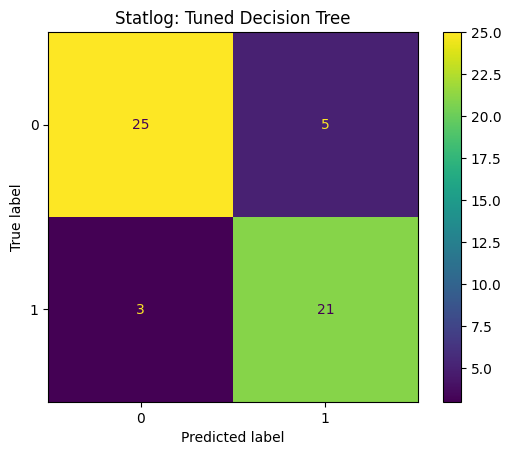

In [52]:
ConfusionMatrixDisplay.from_estimator(
    heart_tuned_tree.best_estimator_,
    X_heart_test,
    y_heart_test
)

plt.title(
    "Statlog: Tuned Decision Tree"
)

plt.show()

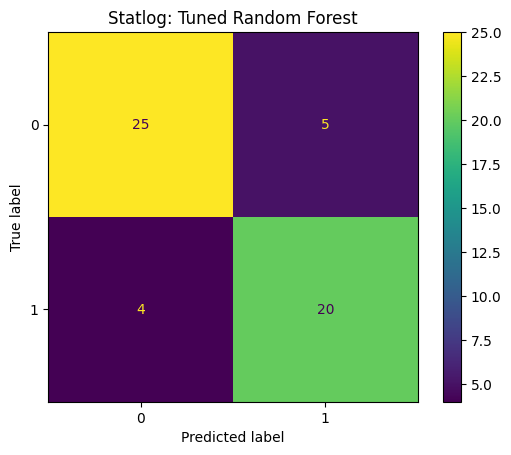

In [53]:
ConfusionMatrixDisplay.from_estimator(
    heart_tuned_forest.best_estimator_,
    X_heart_test,
    y_heart_test
)

plt.title(
    "Statlog: Tuned Random Forest"
)

plt.show()

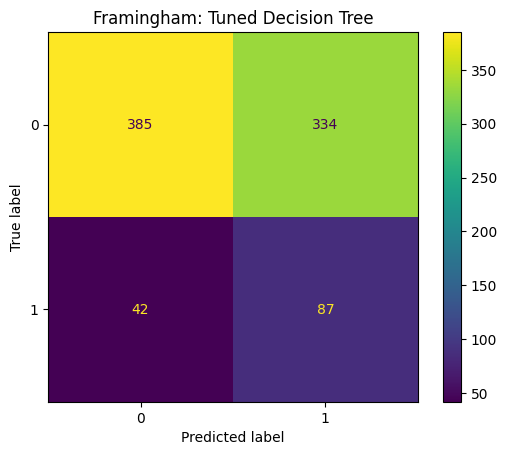

In [54]:
ConfusionMatrixDisplay.from_estimator(
    framingham_tuned_tree.best_estimator_,
    X_framingham_test,
    y_framingham_test
)

plt.title(
    "Framingham: Tuned Decision Tree"
)

plt.show()

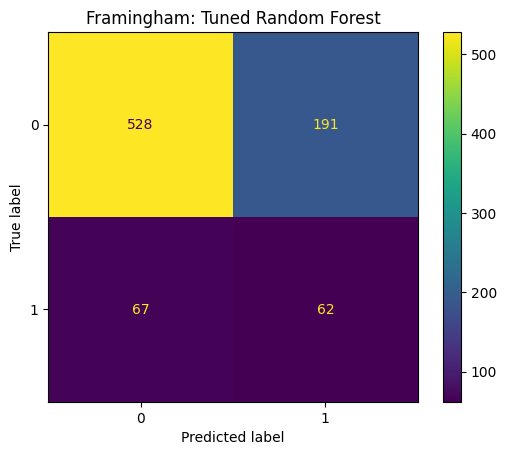

In [56]:
ConfusionMatrixDisplay.from_estimator(
    framingham_tuned_forest.best_estimator_,
    X_framingham_test,
    y_framingham_test
)

plt.title(
    "Framingham: Tuned Random Forest"
)

plt.show()

### Confusion-Matrix Interpretation

The Statlog decision tree correctly classified 25 negative cases and 21 positive cases. It produced 5 false
positives and only 3 false negatives.

The Statlog random forest correctly classified 25 negative cases and 20 positive cases, with 5 false positives
and 4 false negatives. This explains why the decision tree has slightly higher recall and F1 at the default
classification threshold.

The Framingham decision tree correctly identified 87 of the 129 positive CHD cases but produced 334 false
positives. It missed 42 positive cases.

The Framingham random forest identified fewer positive cases, with 62 true positives and 67 false negatives,
but reduced false positives substantially from 334 to 191.

Therefore, the Framingham models illustrate a clear sensitivity tradeoff. The decision tree is more aggressive
about predicting the positive class and achieves greater recall, while the random forest is more selective and
produces better overall accuracy, precision, F1, and ROC AUC.

## Final ROC Curves

ROC curves evaluate how well the final tree-based models distinguish positive from negative cardiovascular
outcomes across different probability thresholds.

ROC AUC values closer to 1 indicate stronger discrimination.

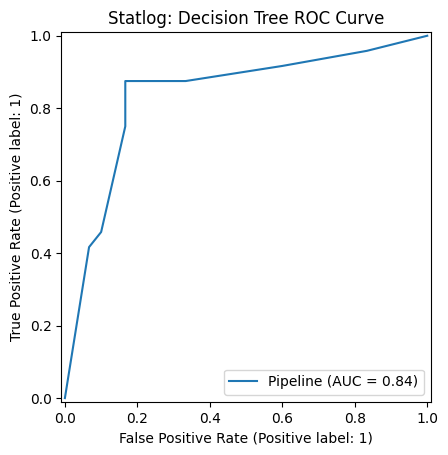

In [57]:
RocCurveDisplay.from_estimator(
    heart_tuned_tree.best_estimator_,
    X_heart_test,
    y_heart_test
)

plt.title(
    "Statlog: Decision Tree ROC Curve"
)

plt.show()

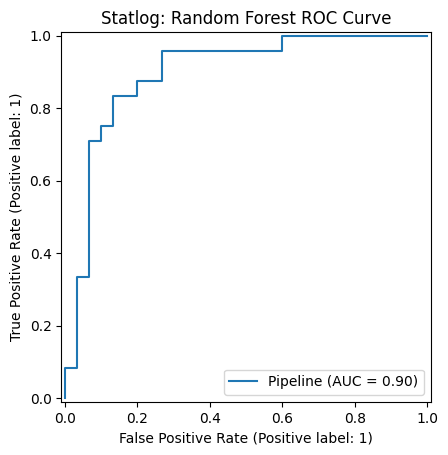

In [58]:
RocCurveDisplay.from_estimator(
    heart_tuned_forest.best_estimator_,
    X_heart_test,
    y_heart_test
)

plt.title(
    "Statlog: Random Forest ROC Curve"
)

plt.show()

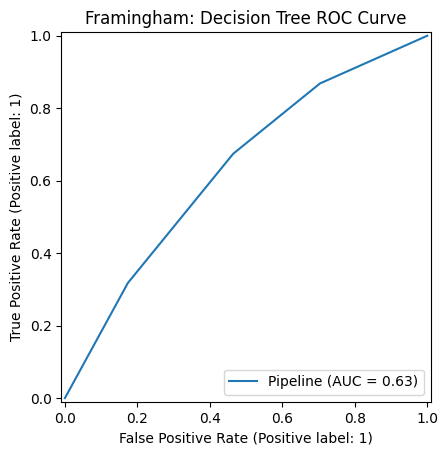

In [59]:
RocCurveDisplay.from_estimator(
    framingham_tuned_tree.best_estimator_,
    X_framingham_test,
    y_framingham_test
)

plt.title(
    "Framingham: Decision Tree ROC Curve"
)

plt.show()

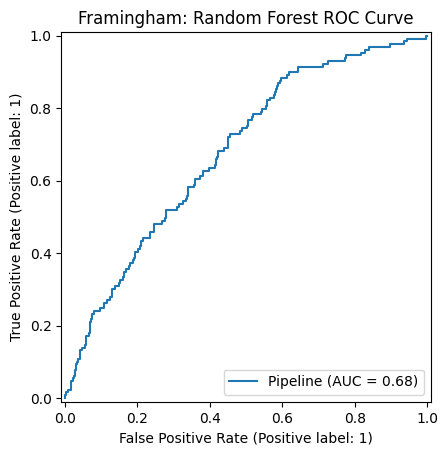

In [60]:
RocCurveDisplay.from_estimator(
    framingham_tuned_forest.best_estimator_,
    X_framingham_test,
    y_framingham_test
)

plt.title(
    "Framingham: Random Forest ROC Curve"
)

plt.show()

### ROC Interpretation

The Statlog random forest achieved the strongest tree-based ROC AUC at 0.896, compared with 0.835 for the
decision tree.

This indicates that the random forest is better able to rank Statlog patients by heart-disease risk across a
range of possible classification thresholds.

For Framingham, ROC AUC increased from 0.633 with the decision tree to 0.680 with the random forest.

Although the Framingham random forest still provides only moderate discrimination, the improvement supports the
idea that aggregating many randomized trees can generalize better than relying on a single tree.

## Random-Forest Feature Importance

Random forests can estimate how much each predictor contributes to reducing impurity across the trees in the
forest.

A feature that is repeatedly useful for making informative splits will generally receive greater feature
importance.

Because categorical predictors were one-hot encoded, their individual encoded columns will first be mapped
back to their original variables. Importances from the encoded categories will then be combined so that the
results can be interpreted at the original feature level.

In [38]:
def get_random_forest_feature_importance(
    search,
    numeric_features,
    binary_features,
    categorical_features,
    dataset_name
):

    pipeline = search.best_estimator_

    preprocessor = pipeline.named_steps[
        "preprocessing"
    ]

    forest = pipeline.named_steps[
        "random_forest"
    ]

    transformed_names = preprocessor.get_feature_names_out()

    importances = forest.feature_importances_

    source_features = []

    for transformed_name in transformed_names:

        clean_name = transformed_name.split(
            "__",
            1
        )[-1]

        original_feature = clean_name

        for feature in categorical_features:

            if (
                clean_name == feature
                or clean_name.startswith(
                    feature + "_"
                )
            ):

                original_feature = feature

                break

        source_features.append(
            original_feature
        )

    importance_df = pd.DataFrame({
        "Feature":
            source_features,

        "Importance":
            importances
    })

    aggregated = (
        importance_df
        .groupby(
            "Feature",
            as_index=False
        )["Importance"]
        .sum()
        .sort_values(
            "Importance",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )

    aggregated[
        "Importance"
    ] = aggregated[
        "Importance"
    ].round(4)

    print(
        dataset_name
    )

    display(
        aggregated
    )

    return aggregated

### Statlog Random-Forest Feature Importance

In [39]:
heart_feature_importance = get_random_forest_feature_importance(
    heart_tuned_forest,
    heart_numeric_features,
    heart_binary_features,
    heart_categorical_features,
    "Statlog Heart Disease Dataset"
)

Statlog Heart Disease Dataset


,Feature,Importance
0,thal,0.2035
1,cp,0.1548
2,ca,0.1444
3,oldpeak,0.1116
4,slope,0.1002
5,thalach,0.0732
6,exang,0.0616
7,age,0.0429
8,sex,0.0413
9,chol,0.0361


### Framingham Random-Forest Feature Importance

In [40]:
framingham_feature_importance = get_random_forest_feature_importance(
    framingham_tuned_forest,
    framingham_numeric_features,
    framingham_binary_features,
    framingham_categorical_features,
    "Framingham Heart Study Dataset"
)

Framingham Heart Study Dataset


,Feature,Importance
0,age,0.2854
1,sysBP,0.1654
2,diaBP,0.0932
3,glucose,0.0713
4,totChol,0.0693
5,prevalentHyp,0.0646
6,BMI,0.0638
7,cigsPerDay,0.0570
8,heartRate,0.0417
9,education,0.0309


### Feature-Importance Visualizations

The following plots display the highest-ranked original predictors from each tuned random forest.

In [41]:
def plot_feature_importance(
    importance_df,
    dataset_name,
    top_n=10
):

    plot_data = (
        importance_df
        .head(
            top_n
        )
        .sort_values(
            "Importance",
            ascending=True
        )
    )

    plt.figure(
        figsize=(8, 6)
    )

    plt.barh(
        plot_data["Feature"],
        plot_data["Importance"]
    )

    plt.xlabel(
        "Feature Importance"
    )

    plt.ylabel(
        "Feature"
    )

    plt.title(
        f"{dataset_name}: Random-Forest Feature Importance"
    )

    plt.show()

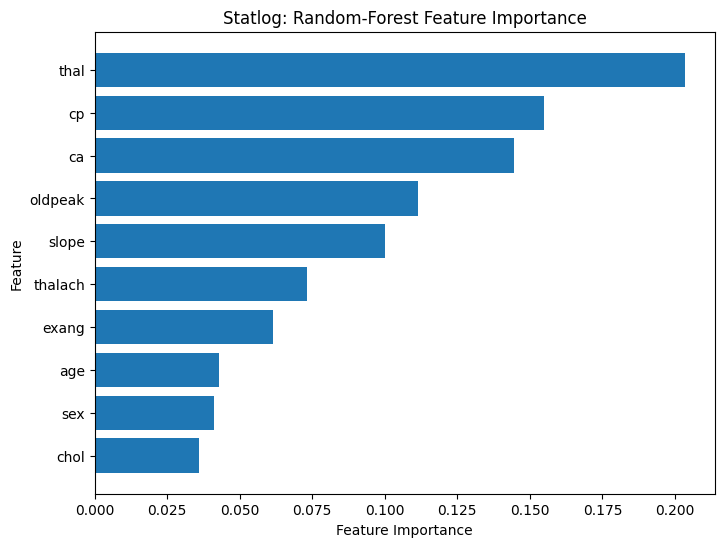

In [42]:
plot_feature_importance(
    heart_feature_importance,
    "Statlog"
)

#### Statlog Feature-Importance Interpretation

The most influential Statlog predictors in the tuned random forest were:

1. `thal`
2. `cp`
3. `ca`
4. `oldpeak`
5. `slope`

These variables accounted for the largest impurity reductions across the trees in the forest.

Chest pain (`cp`) was also selected for the first decision in the earlier entropy analysis, providing consistency
between the single-tree split analysis and the random-forest feature-importance results.

Feature importance should be interpreted as the feature's contribution to the model's splitting decisions rather
than as proof that the feature causes heart disease.

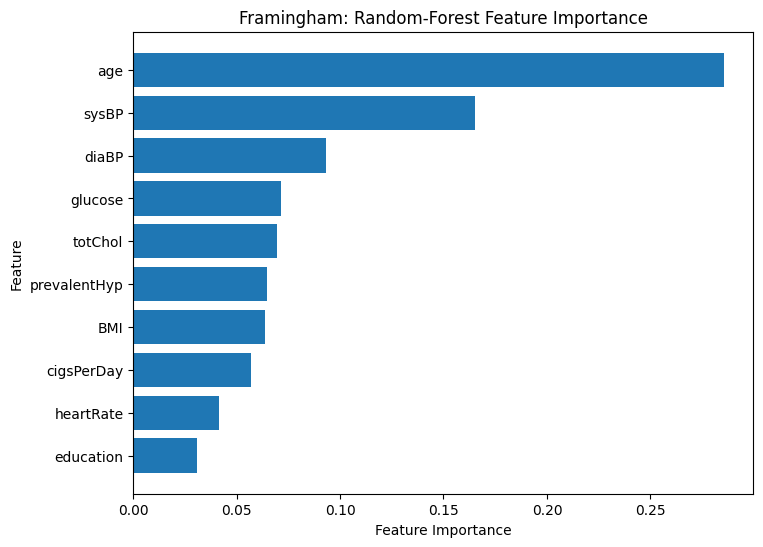

In [43]:
plot_feature_importance(
    framingham_feature_importance,
    "Framingham"
)

#### Framingham Feature-Importance Interpretation

The highest-ranked Framingham predictors were:

1. Age
2. Systolic blood pressure
3. Diastolic blood pressure
4. Glucose
5. Total cholesterol

Age received the greatest importance by a substantial margin.

This agrees with the entropy analysis, where age was selected as the first decision in the one-level
Framingham tree.

The results suggest that age and cardiovascular measurements related to blood pressure and metabolic health
play particularly important roles in the forest's predictions.

These impurity-based importance scores describe how strongly variables contribute to the fitted model and
should not be interpreted as causal effects.

## Decision-Tree Visualization

A decision tree can be interpreted as a sequence of questions.

The visualizations below display the first three levels of each tuned decision tree.

Only the upper portion is shown so that the tree remains readable if the selected model contains additional
levels.

In [44]:
def plot_selected_tree(
    search,
    dataset_name
):

    pipeline = search.best_estimator_

    preprocessor = pipeline.named_steps[
        "preprocessing"
    ]

    tree_model = pipeline.named_steps[
        "decision_tree"
    ]

    feature_names = preprocessor.get_feature_names_out()

    clean_names = [
        name.split(
            "__",
            1
        )[-1]
        for name in feature_names
    ]

    plt.figure(
        figsize=(24, 12)
    )

    plot_tree(
        tree_model,
        feature_names=clean_names,
        class_names=[
            "Class 0",
            "Class 1"
        ],
        filled=True,
        rounded=True,
        max_depth=3,
        fontsize=8
    )

    plt.title(
        f"{dataset_name}: Tuned Decision Tree"
    )

    plt.show()

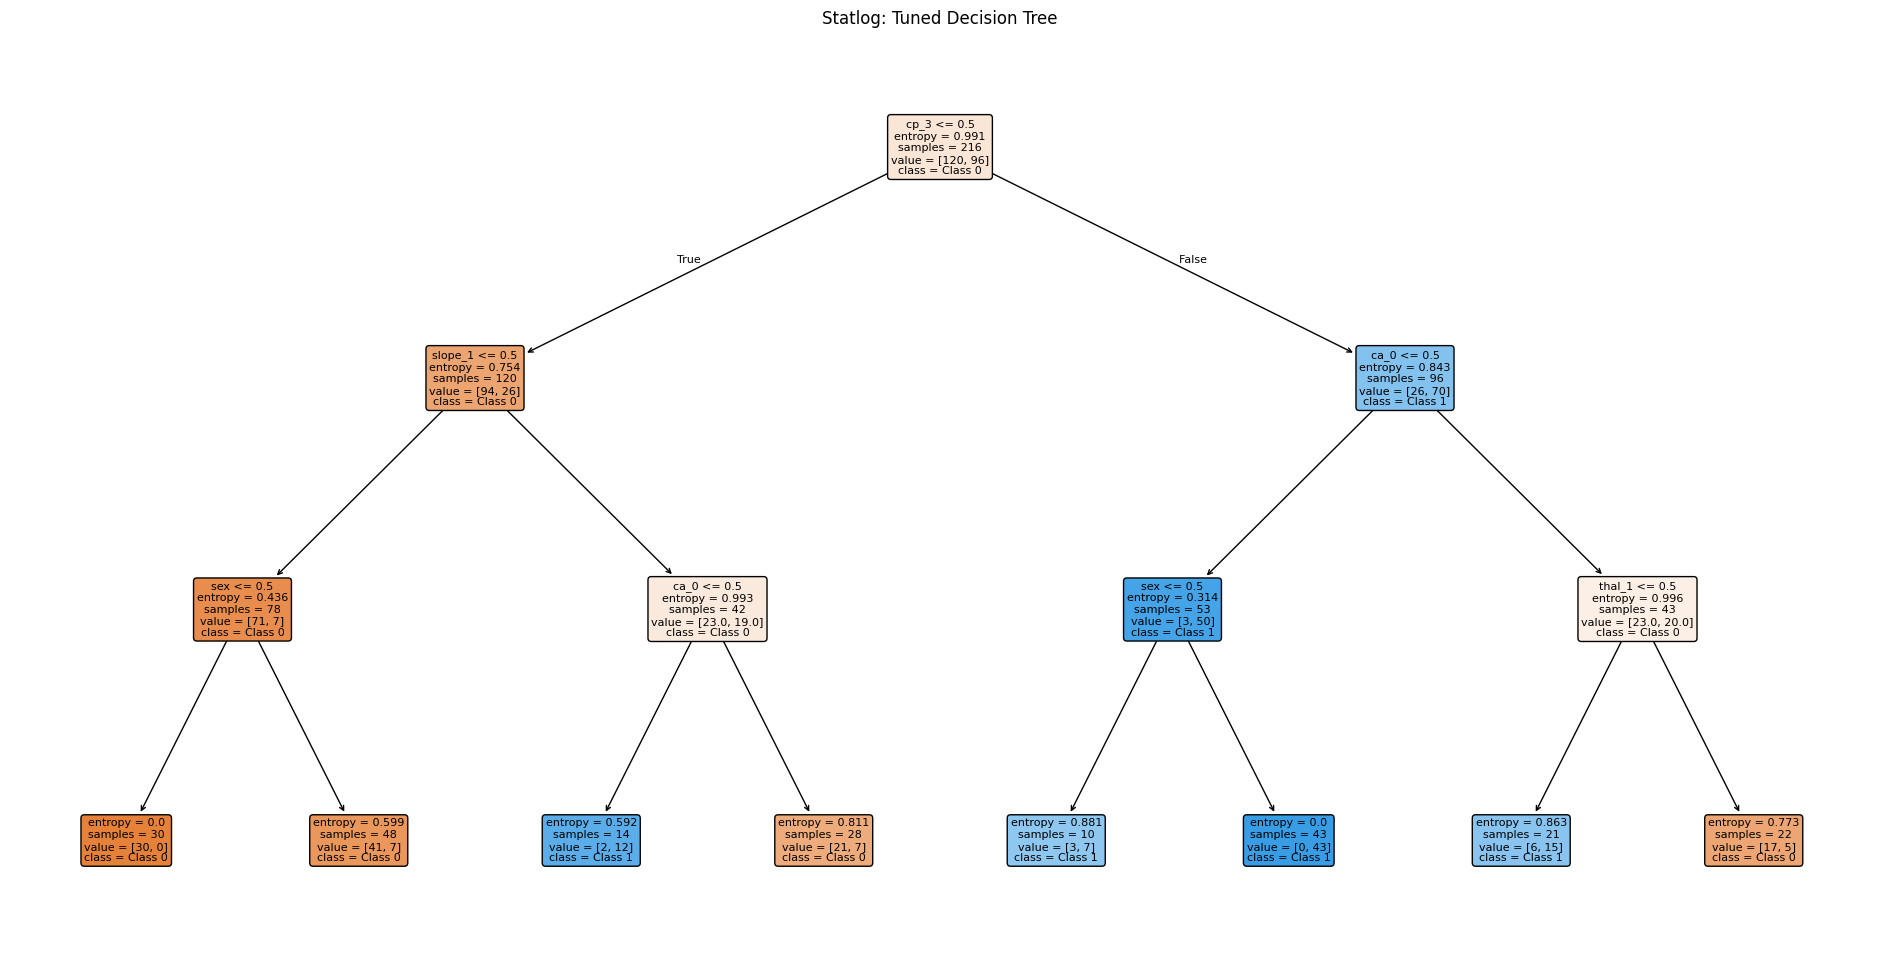

In [61]:
plot_selected_tree(
    heart_tuned_tree,
    "Statlog"
)

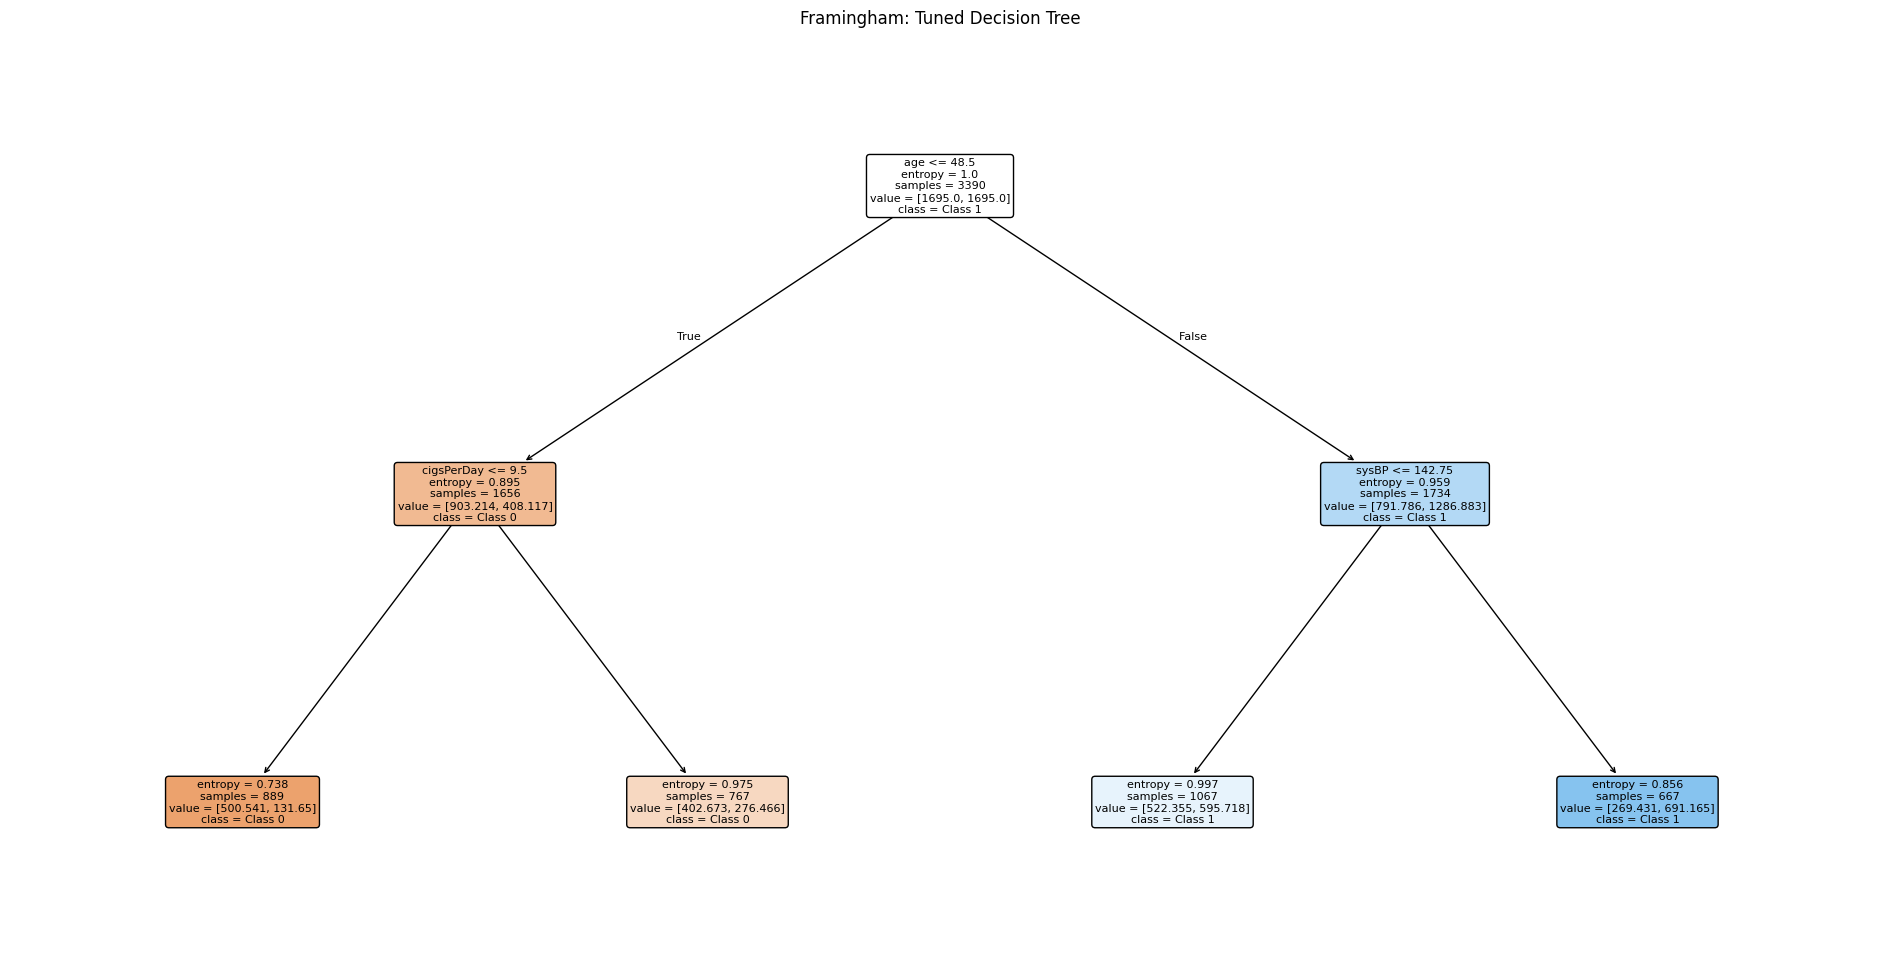

In [62]:
plot_selected_tree(
    framingham_tuned_tree,
    "Framingham"
)

### Decision-Tree Visualization Interpretation

The visualizations show how individual decision trees convert predictor values into sequential classification
rules.

The tuned Statlog tree begins with chest-pain category 3, which agrees with the root-split entropy analysis.
Subsequent decisions use additional cardiovascular variables to divide the observations into increasingly
specific groups.

The tuned Framingham tree is intentionally very shallow because cross-validation selected a maximum depth of
2. Its first decision is based on age at approximately 48.5 years, again matching the earlier information-gain
analysis.

The shallow Framingham structure demonstrates how limiting tree depth can prevent the model from creating many
highly specific rules that fit the training observations but generalize poorly.

## Decision Trees vs Random Forests

A single decision tree has the advantage of interpretability because its sequence of decisions can be visualized
directly.

However, an individual tree can have high variance and can easily overfit if it is allowed to grow too deeply.

Random forests address this weakness by training many trees on different bootstrap samples and introducing
feature randomization during splitting. Their predictions are then aggregated.

In this analysis, the random forests achieved higher cross-validation F1 scores than the tuned individual
decision trees for both datasets.

The random forests also achieved higher held-out ROC AUC for both Statlog and Framingham.

However, the improvement was not universal across every metric. The Statlog decision tree achieved slightly
higher held-out F1 and recall, while the Framingham decision tree achieved substantially higher recall.

Therefore, random forests improved general discrimination and validation performance, but model choice still
depends on the specific evaluation metric and prediction objective.

## Expected and Unexpected Findings

Several findings were consistent with the concepts covered this week.

The clearest expected result was decision-tree overfitting. Increasing tree depth caused training F1 to approach
or reach 1.000, while cross-validation performance stopped improving or declined.

It was also expected that Framingham would remain more difficult than Statlog because the positive CHD outcome
is relatively rare.

One interesting result was that feature randomization by itself did not improve F1 in the initial random-forest
comparison. In both datasets, using a square-root subset of predictors produced similar or slightly lower F1
than allowing all features. However, ROC AUC improved, and the final tuned random forests selected square-root
feature randomization for both datasets.

Another notable result was that the very shallow Framingham decision tree achieved the greatest recall among the
final tree-based models. This shows that a simpler model can sometimes identify the minority class aggressively
even though its overall accuracy and discrimination are lower.

The results emphasize that model complexity should be judged using validation performance rather than assuming
that a more complex model is automatically better.

## Relationship to Previous Analysis

Earlier exploratory analysis identified age, blood pressure, cholesterol, glucose, chest-pain characteristics,
exercise-related measures, and other cardiovascular variables as potentially useful predictors.

Week 4 used logistic regression and showed that Statlog was relatively easy to classify, while Framingham
required special attention to class imbalance.

Week 5 produced a similar pattern with SVMs. Statlog achieved strong discrimination, while Framingham remained
substantially more difficult even with nonlinear kernels.

Week 6 reinforces these findings using tree-based models.

For Statlog, variables such as chest pain, thalassemia, number of major vessels, ST depression, and slope were
important to the tree-based predictions.

For Framingham, age and blood-pressure-related variables were among the most influential predictors.

The tree-based analysis additionally demonstrates nonlinear threshold relationships and interactions without
requiring those relationships to be specified explicitly in advance.

## Optimal Tree-Based Modeling Strategy

For Statlog, both the tuned decision tree and random forest provide useful classification performance.

The decision tree offers greater interpretability and slightly higher F1 and recall at the default threshold.
However, the random forest provides stronger ROC AUC and higher cross-validation F1, indicating more robust
overall discrimination.

If interpretability and a compact set of explicit clinical rules are priorities, the tuned decision tree is a
reasonable choice. If broader predictive discrimination and reduced dependence on a single tree are priorities,
the random forest is preferable.

For Framingham, the random forest provides the stronger overall tree-based model because it achieves higher
accuracy, precision, F1, and ROC AUC than the decision tree.

However, if maximizing sensitivity to positive CHD cases were the primary objective, the shallow balanced
decision tree offers higher recall.

Therefore, the optimal modeling strategy depends on the practical cost of false negatives and false positives
rather than on a single performance statistic.

# Week 6 Overall Conclusion

Week 6 applied decision trees, entropy and information gain, complexity control, random forests, feature
randomization, hyperparameter tuning, and feature-importance analysis to the Statlog Heart Disease and
Framingham Heart Study datasets.

The information-gain analysis selected chest-pain category 3 as the first Statlog split and age at approximately
48.5 years as the first Framingham split.

The tree-depth experiments demonstrated clear overfitting. Deep and unrestricted trees achieved extremely high
training performance, including training F1 scores of 1.000, without producing equivalent cross-validation
performance.

Cross-validation therefore favored constrained decision trees. The final Statlog tree used maximum depth 3 and
the final Framingham tree used maximum depth 2.

Random forests combined many trees using bootstrap aggregation and feature randomization. Their cross-validation
F1 scores exceeded those of the final individual decision trees for both datasets.

On the held-out test data, the Statlog decision tree achieved an F1 score of 0.840, while the Statlog random
forest achieved 0.816. However, the random forest achieved the stronger ROC AUC of 0.896.

For Framingham, the random forest achieved an F1 score of 0.325 and ROC AUC of 0.680, compared with 0.316
and 0.633 for the decision tree. The decision tree nevertheless achieved higher recall because it classified
positive CHD cases more aggressively.

Random-forest feature importance identified thalassemia, chest pain, number of major vessels, ST depression, and
slope as leading Statlog predictors. For Framingham, age, systolic blood pressure, diastolic blood pressure,
glucose, and total cholesterol were the most influential features.

Overall, Week 6 demonstrates that tree-based models can capture nonlinear relationships and provide interpretable
decision structures, but unrestricted decision trees can overfit severely. Controlling tree complexity and
aggregating randomized trees can improve generalization, while the best model still depends on the dataset and
the relative importance of different classification errors.

## AI Use Disclosure

ChatGPT was used as an assistive tool to help structure portions of the Jupyter Notebook code and to help
organize and articulate formal written interpretations after the models had been run. The underlying datasets,
model execution, generated outputs, numerical results, and visualizations were produced within the Jupyter
Notebook and reviewed before the written interpretations were added.